# 0. Notes

- To run this notebook you will need to [install Jupyter](https://jupyter.org/install), i.e., `pip install notebook`
    - If working in VS Code, which we recommend, activate your Python environment by selecting the appropriate kernel
- This assignment is structured like a tutorial. The notebook provides examples, plots, and suggested workflows, while the comments in `mp4.py` specify function inputs and outputs
- After changing `mp4.py`, you may need to rerun imports or restart the notebook kernel
- Most functions are short. Understand each function's **inputs and outputs** before coding, and use vectorized **NumPy** operations where the instructions require them
- You **do not** need to submit to Gradescope to test your code. We supply all necessary tests in `tests.py`, and these are the same tests as the autograder
- Submit only `mp4.py` and `predicate_classifier.py`. Do not submit `tests.py`, `main.py`, `planar_arm.py`, the notebook, or the data files
- Before submitting, comment out or remove debugging print statements, since excessive printing can slow down the autograder

# 1. Setting up linear regression

In this part of the assignment you will set up the necessary code for doing linear regression. Namely you will implement:
- create_linear_data(num_samples, slope, intercept, x_range, noise)
- get_simple_linear_features(x)
- linear_prediction(x, A, get_modified_features)
- mse_loss(y_pred, y_true)
- compute_model_error(x, y, A, get_modified_features)

We'll tackle these one at a time below.

In [1]:
# some generic useful imports - this is ALL you need
import numpy as np
import matplotlib.pyplot as plt
import tests
# the lines below ensure that you can modify mp4.py and imported files update accordingly
%load_ext autoreload
%autoreload 2

## create_linear_data

To do linear regression, or any machine learning, we need data.

For now you will be *synthesizing* your own data. Given a `slope` and `intercept`, create artificial `x` and noisy `y` values. Sample each `x_i` uniformly from the interval `[x_range[0], x_range[1]]`, and compute

$$
y_i = \text{slope} \cdot x_i + \text{intercept} + \epsilon_i
$$

where each $\epsilon_i$ is sampled uniformly from $[-\text{noise}, \text{noise}]$.

`create_linear_data` should return arrays `x` and `y`, each with shape `(num_samples, 1)`. You will find `np.random.rand` useful for sampling both the `x` values and the uniform noise.

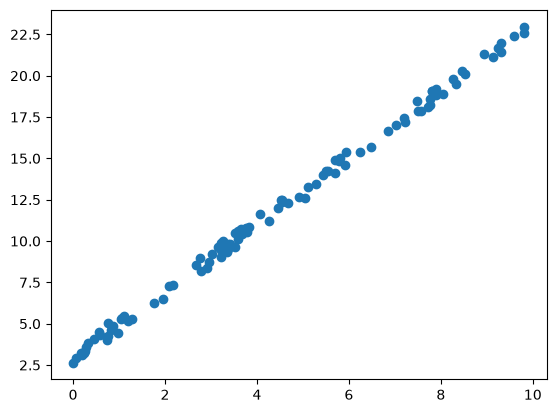

In [2]:
# TODO: fill in the create_linear_data function
# NOTE: DO NOT use for loops
from mp4 import create_linear_data

num_samples = 100
slope = 2
intercept = 3
x_range = [0, 10]
noise = 0.5
x, y = create_linear_data(num_samples, slope, intercept, x_range, noise)
# plot
plt.scatter(x, y)
plt.show()

In [3]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_create_linear_data(num_samples=10, slope=2, intercept=-1, x_range=[-10,10], noise=0)
tests.test_create_linear_data(num_samples=10, slope=-3, intercept=2, x_range=[0,5], noise=0.2)

## get_simple_linear_features and linear_prediction

An extremely important concept in machine learning is **vectorization**.

Instead of writing $y_i=mx_i+b$ for some data $(x_i, y_i)$ we prefer writing $A=\begin{bmatrix} m \\ b \end{bmatrix}$, $X_i=\begin{bmatrix} x_i & 1 \end{bmatrix}$, and thus $y_i=X_iA$. Note that $X_i$ is a $(1,2)$ matrix and $A$ is a $(2,1)$ matrix, so the output $y_i$ is $(1,1)$.

Having written things in this way we no longer think of "slopes" and "intercepts" but rather generic "features". Our features $X_i$ get multiplied by these **parameters** $A$ to compute our output $y_i$. After this transformation we can think of our input as $2$-dimensional, even though the second dimension is always equal to $1$.

For an input matrix $x \in \mathbb{R}^{N \times d}$, `get_simple_linear_features(x)` should return

$$
X = \begin{bmatrix} x & \mathbf{1} \end{bmatrix} \in \mathbb{R}^{N \times (d+1)}.
$$

Now we can write predicted y values for the entire dataset as one matrix multiplication:

$$
Y = XA.
$$

`linear_prediction(x, A, get_modified_features)` should first compute `X = get_modified_features(x)` and then return $\hat{y} = XA$. We can summarize our goal as "find the matrix A which gives good predictions across our dataset". We'll look at what "good" means in the next section.

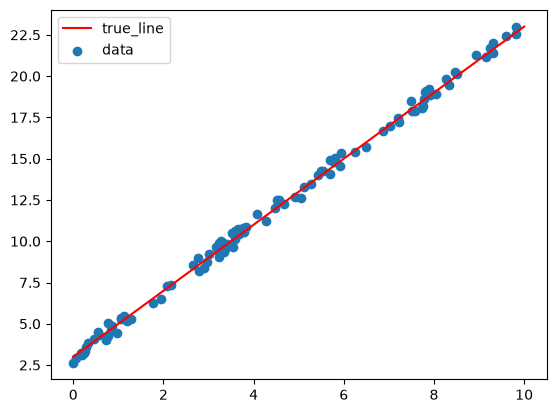

In [4]:
# TODO: fill in the get_simple_linear_features and linear_prediction functions
# NOTE: our solution is ONE line of code for each function! DO NOT use for loops
#       You should use methods like np.concatenate, np.ones, and np.dot
from mp4 import get_simple_linear_features, linear_prediction

# get x_values for plotting the line
x_plot = np.linspace(x_range[0], x_range[1], 1000).reshape(-1, 1)
# now make a matrix A of shape (2, 1) with the slope and intercept
A_true = np.array([[slope], [intercept]])
# now make a prediction
y_hat = linear_prediction(x_plot, A_true, get_simple_linear_features)
# now plot the data and the prediction
plt.plot(x_plot, y_hat, color='red', label="true_line")
plt.scatter(x, y, label='data')
plt.legend()
plt.show()

In [5]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_get_simple_linear_features(num_samples=10, num_features=1)
tests.test_get_simple_linear_features(num_samples=1, num_features=4)
tests.test_linear_prediction()

## mse_loss and compute_model_error

Above we said our goal is to find parameters that make "good" predictions. But what does good mean? In our case, we will look for the set of parameters that *minimize a loss function*. In particular we will use the mean squared error:

$$
\text{MSE}(\hat{Y}, Y) = \frac{1}{N}\sum_i (\hat{y}_i - y_i)^2.
$$

Thanks to our vectorization from before we can rewrite this as:

$$
\text{MSE}(\hat{Y}, Y) = \frac{1}{N}\lVert \hat{Y} - Y \rVert_2^2.
$$

Since our predictions are $\hat{Y} = XA$, our model error is:

$$
L(A, X, Y) = \frac{1}{N}\lVert XA - Y \rVert_2^2.
$$

`mse_loss(y_pred, y_true)` should return this scalar loss. `compute_model_error(x, y, A, get_modified_features)` should compute the model predictions and then return the MSE.

NOTE: The notation $\lVert\cdot\rVert_2$ is the $2$-norm, or Euclidean norm, of a vector. So the loss above is the squared $2$-norm.

In [6]:
# TODO: fill in the mse_loss function
# NOTE: our solution is ONE line of code! Use numpy operations not for loops!
from mp4 import compute_model_error

x, y = create_linear_data(num_samples, slope, intercept, x_range, noise)

# some example models and their corresponding errors
perfect_model = np.array([[slope], [intercept]])
perfect_error = compute_model_error(x, y, perfect_model, get_simple_linear_features)

bad_model = np.array([[slope + 1], [intercept + 1]])
bad_error = compute_model_error(x, y, bad_model, get_simple_linear_features)

really_bad_model = np.array([[-slope], [-intercept]])
really_bad_error = compute_model_error(x, y, really_bad_model, get_simple_linear_features)

# NOTE: perfect error is not zero because of the noise
print(f"Perfect model error: {perfect_error}")
print(f"Bad model error: {bad_error}")
print(f"Really bad model error: {really_bad_error}")

Perfect model error: 0.08398331692142919
Bad model error: 43.5389668540005
Really bad model error: 787.0959805842939


In [7]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_mse_loss()

# 2. Analytical linear regression

Great, so we have data, we can vectorize it, and we can compute some error. But how do we actually find the right set of parameters? The answer is to *minimize the loss*. There are many ways to minimize a function. First we'll look at a simple approach from calculus: to minimize a function take the derivative, set it equal to zero, and solve the equation.

Specifically, we take the partial derivative of our *loss* with respect to our *parameters*:

$$
\frac{\partial L}{\partial A}
= \frac{\partial}{\partial A}\left(\frac{1}{N}\lVert XA-Y\rVert_2^2\right)
= \frac{2}{N}X^T(XA-Y).
$$

Setting this equal to zero gives:

$$
X^T(XA-Y) = 0
$$

$$
X^TXA = X^TY
$$

$$
A = (X^TX)^{-1}X^T Y.
$$

You're not expected to know matrix derivatives, but you can intuitively see how we got the derivative by imagining these were real numbers: if we had no matrices, our loss might look like $L(a,x,y) = (ax - y)^2$, and the derivative with respect to $a$ is $2x(ax-y)$.

Fill in `analytical_linear_regression(X, y)` with the expression above. It should return an array with shape `(num_modified_features, 1)`.

True slope: 2, True intercept: 3
Predicted slope: 1.9795561770399648, Predicted intercept: 3.143348723737767


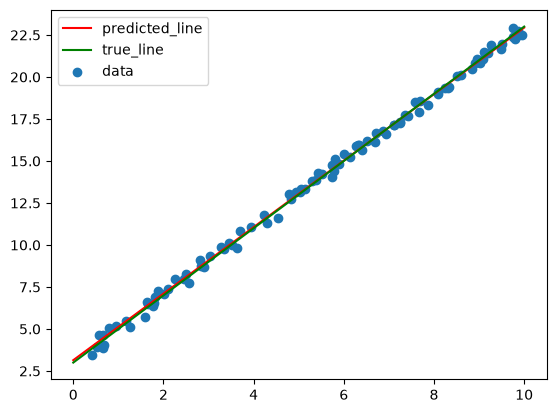

True slope: 2, True intercept: 3
Predicted slope: 1.549282154035232, Predicted intercept: 5.827461031773305


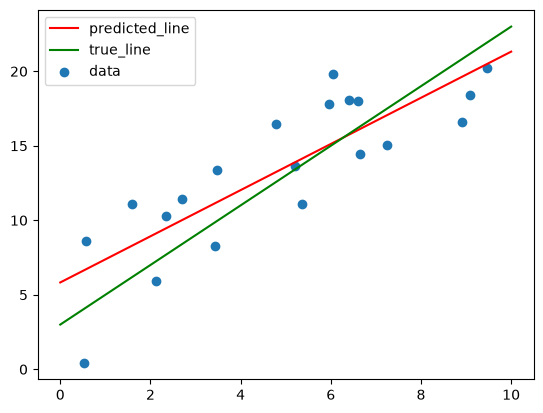

In [8]:
# TODO: fill in the analytical_linear_regression function. DO NOT use for loops!
from mp4 import analytical_linear_regression
# create data
num_samples = 100
slope = 2
intercept = 3
x_range = [0, 10]
noise = 0.5
x, y = create_linear_data(num_samples, slope, intercept, x_range, noise)
# transform x into features (add column of 1's)
X = get_simple_linear_features(x)
# find the analytical solution
predicted_A = analytical_linear_regression(X, y)
print(f"True slope: {slope}, True intercept: {intercept}")
print(f"Predicted slope: {predicted_A[0, 0]}, Predicted intercept: {predicted_A[1, 0]}")

# plot
y_hat = linear_prediction(x_plot, predicted_A, get_simple_linear_features)
y_true = linear_prediction(x_plot, perfect_model, get_simple_linear_features)
plt.plot(x_plot, y_hat, color='red', label="predicted_line")
plt.plot(x_plot, y_true, color='green', label="true_line")
plt.scatter(x, y, label='data')
plt.legend()
plt.show()

# Now see what happens with larger noise and few samples
num_samples = 20
large_noise = 5.0
x, y = create_linear_data(num_samples, slope, intercept, x_range, large_noise)
X = get_simple_linear_features(x)
predicted_A = analytical_linear_regression(X, y)
print(f"True slope: {slope}, True intercept: {intercept}")
print(f"Predicted slope: {predicted_A[0, 0]}, Predicted intercept: {predicted_A[1, 0]}")

# plot
y_hat = linear_prediction(x_plot, predicted_A, get_simple_linear_features)
y_true = linear_prediction(x_plot, perfect_model, get_simple_linear_features)
plt.plot(x_plot, y_hat, color='red', label="predicted_line")
plt.plot(x_plot, y_true, color='green', label="true_line")
plt.scatter(x, y, label='data')
plt.legend()
plt.show()

In [9]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_analytical_linear_regression()

# 3. Gradient descent

In practice, such as with neural networks, we can often *take* the derivative but *not solve for when it is equal to zero*. Now you will implement gradient descent, which uses the derivative to iteratively update the parameters. As above, our derivative is:

$$
\frac{\partial L}{\partial A} = \frac{2}{N}X^T(XA-Y).
$$

Implement `get_linear_regression_gradient(A, X, y)` to return this gradient with the same shape as `A`.

Gradient descent starts from `A_init` and repeatedly computes:

$$
A \leftarrow A - \alpha \frac{\partial L}{\partial A}
$$

where $\alpha$ is the `learning_rate`.

Now implement `gradient_descent`.

- `gradient_descent` takes as input a function called `get_gradient`, which only depends on the parameters. See the code example below for how we pass `get_linear_regression_gradient` into `gradient_descent`
- The same gradient descent code can be reused for different losses because the gradient function is provided as an argument
- Notice the TODO below. You should modify the `learning_rate` and `num_iterations` yourself until you get good results

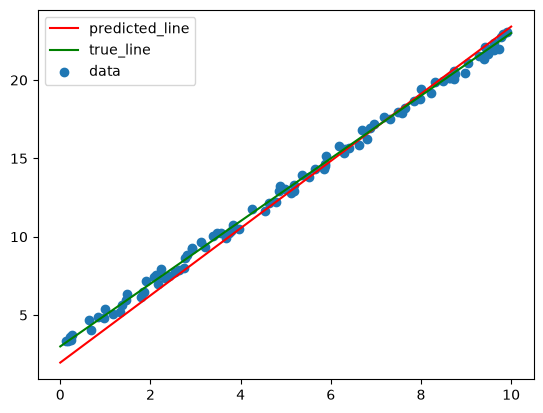

In [10]:
from mp4 import get_linear_regression_gradient, gradient_descent

# initialize data
num_samples = 100
slope = 2
intercept = 3
x_range = [0, 10]
noise = 0.5
x, y = create_linear_data(num_samples, slope, intercept, x_range, noise)
X = get_simple_linear_features(x)

# random initialization of parameters
A_init = np.random.randn(2, 1)

# TODO: play around with these parameters to see how they affect the results
learning_rate = 0.01
num_iterations = 200

# *** notice how we fix X and y as inputs to get_linear_regression_gradient in order to compute get_gradient ***
get_gradient = lambda A: get_linear_regression_gradient(A, X, y)

# do gradient descent
predicted_A = gradient_descent(get_gradient, A_init, learning_rate, num_iterations)

# plot
y_hat = linear_prediction(x_plot, predicted_A, get_simple_linear_features)
y_true = linear_prediction(x_plot, perfect_model, get_simple_linear_features)
plt.plot(x_plot, y_hat, color='red', label="predicted_line")
plt.plot(x_plot, y_true, color='green', label="true_line")
plt.scatter(x, y, label='data')
plt.legend()
plt.show()

In [11]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_linear_regression_gradient()
tests.test_gradient_descent()

## Stochastic gradient descent (SGD)

Imagine we had $1,000,000$ data points, which is a small fraction of the amount of data used to train some models, such as large language models. In every iteration of gradient descent we would compute using all the data at once only to make a small update to our parameters. This can be quite slow. For example, if we had $100$ features, this would entail doing over $100,000,000$ mathematical operations just to compute $XA$.

Stochastic gradient descent makes a simple change to gradient descent: each time we update our parameters, we compute the gradient using just a batch of data. This means our gradient is a *worse approximation of the true gradient*, because our data has noise and the batch is only part of the dataset. As a result we usually have to lower the learning rate a little. You can think of learning rate as how much you trust the direction the gradient is telling you to go.

Now implement `stochastic_gradient_descent`. Each epoch should represent one pass through the entire dataset. For each epoch:

1. Create a random permutation of the dataset indices
2. Split those indices into batches of size `batch_size`
3. For each batch, compute the batch gradient using `get_batch_gradient(A, indices)`
4. Update `A` using the same gradient descent update rule

Make sure to shuffle before each epoch. `np.random.permutation` is useful here.

Notice how `stochastic_gradient_descent` uses a `get_batch_gradient` function instead of `get_gradient`. The only difference is that `get_batch_gradient` takes as input a list of indices and then subselects from the data to compute the gradient. Again, see below for sample usage.

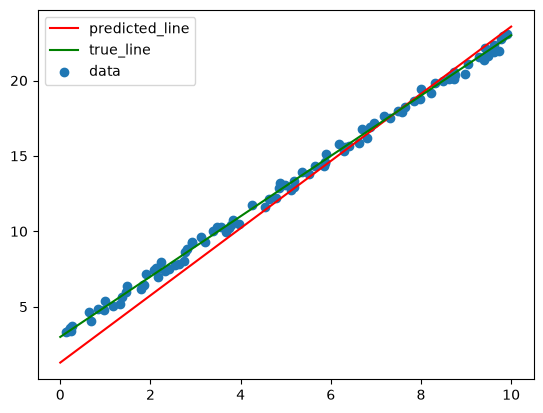

In [12]:
# TODO: fill in the stochastic_gradient_descent function
from mp4 import stochastic_gradient_descent

# initialize data
num_samples = 100
slope = 2
intercept = 3
x_range = [0, 10]
noise = 0.5
x, y = create_linear_data(num_samples, slope, intercept, x_range, noise)
X = get_simple_linear_features(x)

# stochastic gradient descent parameters 
A_init = np.random.randn(2, 1)
learning_rate = 0.01
num_epochs = 10
batch_size = 10
data_size = len(x)
# *** notice how we now take indices as input to get a subset of the data ***
get_batch_gradient = lambda A, indices: get_linear_regression_gradient(A, X[indices], y[indices])

predicted_A = stochastic_gradient_descent(
    get_batch_gradient, A_init, learning_rate, num_epochs, data_size, batch_size)

# plot
y_hat = linear_prediction(x_plot, predicted_A, get_simple_linear_features)
y_true = linear_prediction(x_plot, perfect_model, get_simple_linear_features)
plt.plot(x_plot, y_hat, color='red', label="predicted_line")
plt.plot(x_plot, y_true, color='green', label="true_line")
plt.scatter(x, y, label='data')
plt.legend()
plt.show()

In [13]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_stochastic_gradient_descent()

# 4. Sine data and feature transforms

Now we will fit a function to sine data while still using linear regression. How is this possible? A line cannot fit a sine curve!

The trick is that linear regression is linear in the transformed features, not necessarily linear in the original input. We can fit more complex nonlinear functions of the original input by transforming the input features and then doing linear regression. Intuitively, this is similar to what a deep neural network does, where the last layer computes a linear function of hidden-layer activations that are nonlinear functions of the original input.

First let's create synthetic data. `create_sine_data(num_samples, x_range, noise)` should return arrays `x` and `y`, each with shape `(num_samples, 1)`. Sample each $x_i$ uniformly from `[x_range[0], x_range[1]]`, and compute

$$
y_i = \sin(x_i) + \epsilon_i
$$

where each $\epsilon_i$ is sampled uniformly from $[-\text{noise}, \text{noise}]$. Here $U(a,b)$ means uniform distribution between $a$ and $b$.

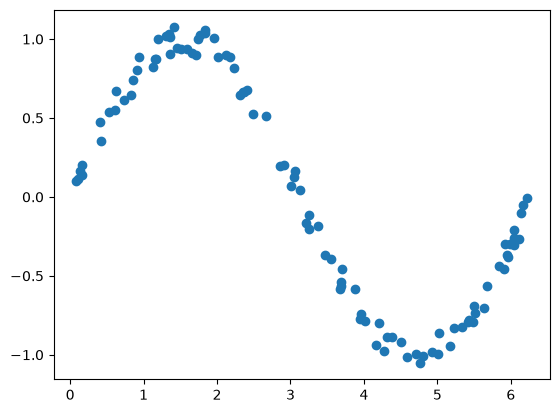

In [14]:
# TODO: fill in the create_sine_data function
from mp4 import create_sine_data

num_samples = 100
x_range = [0, 2 * np.pi]
noise = 0.1
x, y = create_sine_data(num_samples, x_range, noise)

# plot
plt.scatter(x, y)
plt.show()

In [15]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_create_sine_data()

## get_polynomial_features

Obviously a linear function cannot fit this data, but a polynomial function could. In order to do polynomial regression we modify our model from $y=mx+b$ to

$$
y=a_k x^k + a_{k-1} x^{k-1} + \dots + a_1 x + a_0
$$

for some degree $k$.

The easiest way to think of this is as a feature transform. Before we transformed our features as follows:

$$
X = \begin{bmatrix} x_{0} \\ x_{1} \\ \vdots \\ x_{n-1} \end{bmatrix}
\to
X_{\text{linear}} = \begin{bmatrix} x_{0} & 1 \\ x_{1} & 1 \\ \vdots & \vdots \\ x_{n-1} & 1 \end{bmatrix}.
$$

We can think of this as:

$$
X_{\text{linear}} = \begin{bmatrix} X^1 & X^0 \end{bmatrix}.
$$

Now we will compute a more general transform:

$$
X_{\text{polynomial}} = \begin{bmatrix} X^k & X^{k-1} & \dots & X^1 & X^0 \end{bmatrix}.
$$

For an input matrix $x \in \mathbb{R}^{N \times d}$, `get_polynomial_features(x, degree)` should return a matrix with shape

$$
(N,\ d(\text{degree}+1)).
$$

For this sine-fitting part, `num_features` is usually $1$, but your implementation should handle multiple input features. Notice that the final two columns are exactly what we implemented in `get_simple_linear_features`. You can think of this new feature transform as a generalization of the simple linear features we used earlier.

After this feature transform we can once again do plain old linear regression, meaning compute $A$ such that the MSE loss is minimized for model $Y = XA$.

Notice the TODO below. You should play around with the degree of the polynomial. Obviously `degree=1` is insufficient.

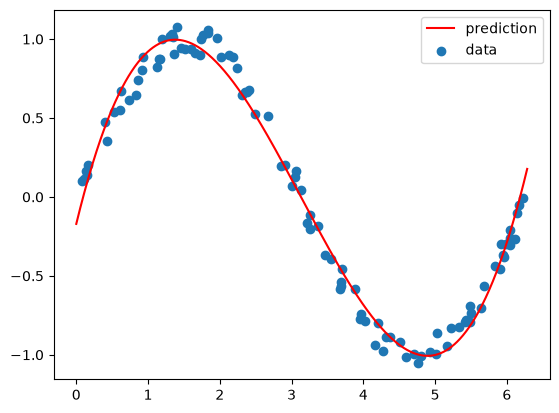

In [16]:
# TODO: fill in the get_polynomial_features function
from mp4 import get_polynomial_features

# TODO: you should change the degree to see how the model fits the data
degree = 3
X = get_polynomial_features(x, degree=degree)
# NOTE: we're using analytical linear regression here, 
# but you can substitute in gradient descent or stochastic gradient descent
A_sine = analytical_linear_regression(X, y)

# plot
x_plot = np.linspace(x_range[0], x_range[1], 1000).reshape(-1, 1)
y_hat = linear_prediction(x_plot, A_sine, lambda x: get_polynomial_features(x, degree=degree))
plt.plot(x_plot, y_hat, color='red', label="prediction")
plt.scatter(x, y, label='data')
plt.legend()
plt.show()

In [17]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_get_polynomial_features(num_data=10, num_features=1, degree=3)
tests.test_get_polynomial_features(num_data=10, num_features=2, degree=3)
tests.test_get_polynomial_features(num_data=100, num_features=1, degree=1)

# 5. Inverse kinematics via gradient descent

The gradient descent algorithm is extremely general and is used in a wide range of applications. We will now see a simplified application to robotics, namely inverse kinematics.

In robotics, forward kinematics refers to the process of computing geometries from configurations. For example, if our robot is a rectangle at position $(x,y,\theta)$, where $\theta$ is its orientation, then forward kinematics refers to finding the coordinates of the four corners of this rotated rectangle. If our robot is an arm with three joints described by their respective angles $(\theta_1, \theta_2, \theta_3)$, then forward kinematics computes the line segments for those joints.

Inverse kinematics is the reverse: given a desired position in the real world, compute a configuration that achieves this position. For example, in the case of the 3-joint arm, given an $(x,y)$ coordinate for the tip of the arm, also called the end effector, find joint angles such that the end effector is at that coordinate. This is a one-to-many function. Think of putting your hand on a table and then moving your elbow: your hand stays put but the joint configuration of your arm changes.

In this part, the goal is to move the end effector close to a desired point in the workspace. This is inverse kinematics and *not* motion planning as we are not considering collisions with ourselves or obstacles, though later we will see how we can make our loss function incorporate obstacle avoidance (at which point we are essentially doing trajectory optimization). Later we will see how modifying the loss function can encourage obstacle avoidance.

Let's meet our robot.

Our robot has (4, 2) endpoints
The arm base is fixed at (0,0)
The end effector position is [-0.47038649  2.67726613]


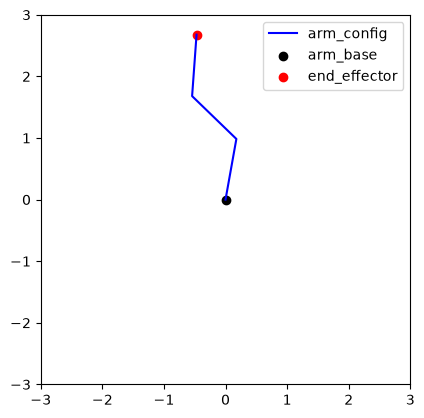

In [18]:
# TODO: you don't need to write any code, but you should familiarize yourself with the Arm class
#       namely you should understand what the code below is doing, you may want to play around with it a little
from planar_arm import Arm

# create an Arm object with 3 joints, each has length 1
num_joints = 3
arm_lengths = np.ones(num_joints)
arm = Arm(arm_lengths=arm_lengths)
# draw_space sets the axis limits
arm.draw_space(plt.gca())

# now define a configuration for the arm - meaning 3 joint angles
# NOTE: joint angles are in degrees
config = np.random.rand(num_joints) * 360
# draw the configuration
arm.draw_config(plt.gca(), config, color='blue', label='arm_config')
plt.scatter(0, 0, color='black', label='arm_base')

# compute the end effector position
# forward_kinematics returns the (x,y) positions of each joint and the end effector
forward_kinematics = arm.forward_kinematics(config)
print(f"Our robot has {forward_kinematics.shape} endpoints")
end_effector = forward_kinematics[-1]
print("The arm base is fixed at (0,0)")
print(f"The end effector position is {end_effector}")
# plot the end effector
plt.scatter(end_effector[0], end_effector[1], color='red', label='end_effector')

plt.legend()
plt.show()

## ik_loss

In order to do gradient descent we need a loss function. Fill in `ik_loss(arm, config, goal)`, which should compute the Euclidean distance between the end effector and the goal:

$$
L(q) = \lVert \text{ee}(q) - g \rVert_2.
$$

Here $q$ is the configuration, $g$ is the goal, and $\text{ee}(q)$ is the final point in workspace returned by `arm.forward_kinematics(config)`, i.e., `arm.forward_kinematics(config)[-1]`.

We also provide `ik_loss_with_obstacles`, which adds a penalty for being close to circular obstacles. You do not need to modify this function but feel free to experiment with it.

The code below samples random configurations of the arm until one of them has a loss less than $0.1$, meaning the end effector is close to the goal position. This is one way of doing inverse kinematics, but we'll discuss below a better alternative.

Final loss after 928 samples: 0.09470828495106373


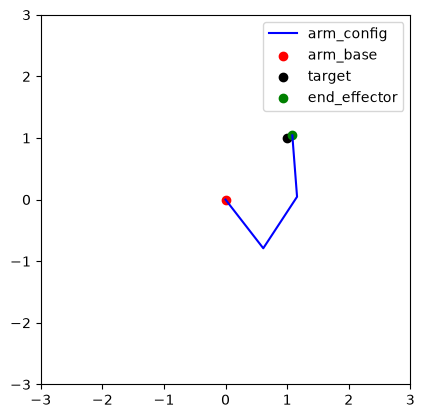

In [19]:
# TODO: fill in the ik_loss function
from mp4 import ik_loss

# let's say we want the end effector to be at (1, 1)
target = np.array([1, 1])

# we will keep sampling configurations until we get close
config = np.random.rand(num_joints) * 360
num_attempts = 0
max_error = 0.1
while ik_loss(arm, config, target) > max_error:
    config = np.random.rand(num_joints) * 360
    num_attempts += 1
final_loss = ik_loss(arm, config, target)
print(f"Final loss after {num_attempts} samples: {final_loss}")

arm.draw_space(plt.gca())
arm.draw_config(plt.gca(), config, color='blue', label='arm_config')
plt.scatter(0, 0, color='red', label='arm_base')
plt.scatter(target[0], target[1], color='black', label='target')
end_effector = arm.forward_kinematics(config)[-1]
plt.scatter(end_effector[0], end_effector[1], color='green', label='end_effector')

plt.legend()
plt.show()

In [20]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_ik_loss()

## estimate_ik_gradient and sample_directions

While we could attempt to analytically compute the gradient of the loss function with respect to the configuration, this is geometrically difficult and can become impossible for more complex robots. Instead, we will use a simple numerical approximation of the gradient based on finite differences and sampling.

Our main idea is to estimate a local gradient direction by sampling the loss function around the current configuration. One simple approach would be to look for the single nearby sample with the largest loss and treat that as the uphill direction. While this matches the basic intuition that gradients point uphill, it is noisy and throws away most of the samples. A more stable idea is to let every sample vote on which way the gradient should point.

Suppose the current configuration is $q$, and we sample unit directions $u_i$. For each sampled direction, we can compute the nearby configuration as

$$
q_i = q + \epsilon u_i
$$

for some small step size $\epsilon$, and therefore the loss at that nearby configuration as $L(q_i)$. Thus our vote for the gradient direction is $L(q_i)u_i$: the higher the loss, the more this direction should contribute to the overall gradient direction. We can average these votes to get a local estimate of the gradient direction:

$$
g = \frac{1}{N}\sum_i L(q_i)u_i.
$$

Then the normalized gradient direction is

$$
\nabla L(q) = \frac{g}{\lVert g \rVert_2}.
$$

As we sample more this becomes a better estimate, but for a small number of samples it can lead to a biased estimate of the direction. To see why, suppose we sample a direction $u_i$ and find that moving in that direction gives a loss of `100`, but the loss at the current configuration is also `100`. Then this direction is not actually uphill.

There are two simple ways to avoid this bias:

1. Subtract the current loss from each vote:

$$
g = \frac{1}{N}\sum_i \left(L(q_i) - L(q)\right)u_i.
$$

2. Sample both $u_i$ and $-u_i$ and compare the loss in both directions:

$$
q_i^+ = q + \epsilon u_i, \quad q_i^- = q - \epsilon u_i,
$$

and thus

$$
g = \frac{1}{N}\sum_i \left(L(q_i^+) - L(q_i^-)\right)u_i.
$$

Implement `sample_directions(num_samples, num_features)` by returning uniformly random unit directions. The result should have shape `(num_samples, num_features)`, and each row should have Euclidean norm 1.

Next implement `estimate_ik_gradient(loss, config, num_samples)`. It should:

1. Sample random directions using `sample_directions`
2. Move a small distance `epsilon` in those directions to get nearby configurations
3. Evaluate the loss at the nearby configurations
4. Estimate an average local direction of increasing loss, debiasing either with the negative directions or by subtracting the current loss
5. Return that direction as a unit vector with shape `(num_features,)`

Gradient descent then subtracts this vector, so the arm moves in a direction that reduces loss.

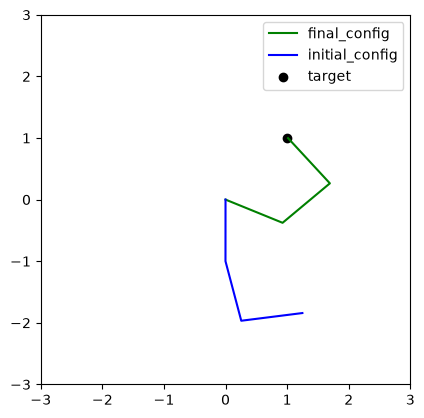

In [21]:
# TODO: fill in the estimate_ik_gradient function
from mp4 import estimate_ik_gradient

# let's say we want the end effector to be at (1, 1)
target = np.array([1, 1])
# we sample num_sample_directions directions to estimate the gradient at each point
num_sample_directions = 20
# our gradient with respect to a config given the target and loss function
loss = lambda config: ik_loss(arm, config, target)
get_gradient = lambda config: estimate_ik_gradient(loss, config, num_samples=num_sample_directions)

# gradient descent parameters
config_init = np.random.rand(num_joints) * 360 # random initialization, this is like A_init
learning_rate = 1.0 # notice a much higher learning rate
num_iterations = 1000 # with 1000 iterations we will get much closer to the target than before with over 1000 samples
final_config = gradient_descent(get_gradient, config_init, learning_rate, num_iterations)

# plot
arm.draw_space(plt.gca())
arm.draw_config(plt.gca(), final_config, color='green', label='final_config')
arm.draw_config(plt.gca(), config_init, color='blue', label='initial_config')
plt.scatter(target[0], target[1], color='black', label='target')
plt.legend()
plt.show()

In [22]:
tests.test_sample_directions()
tests.test_estimate_ik_gradient()

This just shows the initial and final configurations... If you want to see the entire path you can run gradient descent for a few steps and plot each time. If your code above works then you can run `main.py` where we do this for you.

`python3 main.py --data_type ik --method gd --learning_rate 1 --batch_size 20 --plot_iterations 5 --num_iterations 1000`

---

Let's now see what happens when we add obstacles...

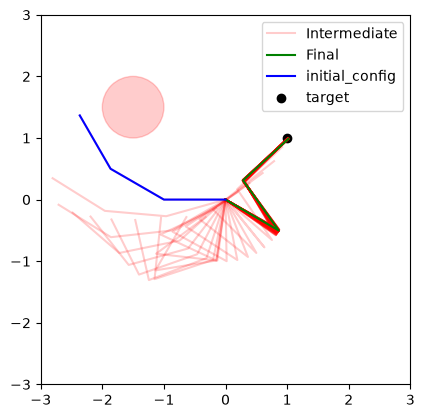

In [23]:
from mp4 import ik_loss_with_obstacles
from main import run_optimization_and_save_intermediates

num_joints = 3 # what if you made this 6?
arm_lengths = np.ones(num_joints)
arm = Arm(arm_lengths=arm_lengths)

# let's say we want the end effector to be at (1, 1)
target = np.array([1, 1])
# obstacles are circles with (x, y, radius)
obstacles = np.array([[-1.5, 1.5, 0.5]])
# draw the obstacles
for obstacle in obstacles:
    plt.gca().add_patch(plt.Circle(obstacle[:2], obstacle[2], color='red', alpha=0.2))

# we sample num_sample_directions directions to estimate the gradient at each point
num_sample_directions = 30
# our gradient with respect to a config
# loss = lambda config: ik_loss(arm, config, target)
loss = lambda config: ik_loss_with_obstacles(arm, config, target, obstacles)
get_gradient = lambda config: estimate_ik_gradient(loss, config, num_samples=num_sample_directions)

# we specifically start the arm to the left of the obstacle
config_init = np.array([180, 30, 30])
if num_joints == 6:
    config_init = np.array([180, 30, 30, 0,0,0])

learning_rate = 1.0
total_iters = 2000

# this is some code from main.py that runs the optimization and saves intermediate steps
optim = lambda A_init, num_iterations: gradient_descent(
            get_gradient=get_gradient,
            A_init=A_init, 
            learning_rate=learning_rate, 
            num_iterations=num_iterations)
A_vals = run_optimization_and_save_intermediates(
    optim, config_init, total_iters=total_iters, plot_iters=20)

for i, A_val in enumerate(A_vals):
    plot_params = {"color": 'red', "alpha": 0.2}
    if i == 0:
        plot_params["label"] = "Intermediate"
    if i == len(A_vals) - 1:
        plot_params = {"color": 'green', "label": "Final"}
    arm.draw_config(plt.gca(), A_val, **plot_params)
# plot
arm.draw_space(plt.gca())
arm.draw_config(plt.gca(), config_init, color='blue', label='initial_config')
plt.scatter(target[0], target[1], color='black', label='target')
plt.legend()
plt.show()

Feel free to play around with the loss function and obstacles... If you give the arm 6 joints does it still get to its goal (change the num_joints to 6)? Can you make it still get to the goal (e.g., try multiplying the obstacle loss by some weight in the `ik_loss_with_obstacles` function...)?

Note: this is not necessary for passing our tests and is purely for your own enjoyment.

# 6. Classification - logistic regression

Above we looked at regression and inverse kinematics. Now we will briefly look at classification, where instead of trying to predict some real number for each input we need to predict a class (either 0 or 1). Also, this time, instead of creating artificial data we will load some data that has been provided for you.

(100, 2)
(100, 1)


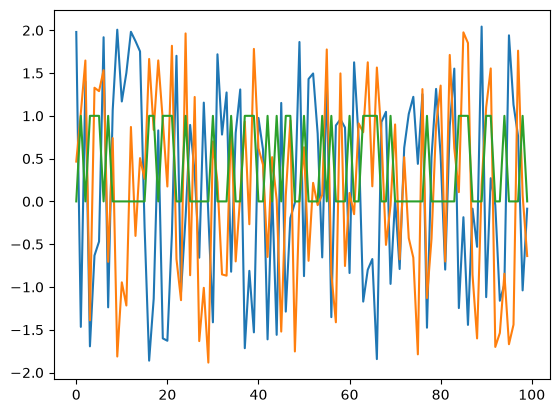

In [24]:
from main import load_data

# load the data
x,y = load_data(0) # you can load_data(0), load_data(1), or load_data(2)

# TODO: examine this data, e.g., plot it, print its shape, etc
print(x.shape)
print(y.shape)

plt.plot(x[:, 0])
plt.plot(x[:, 1])
plt.plot(y)
plt.show()

## Probabilistic view of classification

Instead of training a model to output a *discrete class*, such as 0 or 1, we can train a model to output a *continuous probability* that some input feature belongs to a certain class. In other words, we want $p(y\mid x)$. In this assignment we want $p(y=1 \mid x)$ and $p(y=0 \mid x)$. Since these two values add up to one, we can train a single model $f(x)$ to predict $p(y=1 \mid x)$.

### Model

Our goal is to approximate the 0-1 function with a continuous one. Such a function is called a *sigmoid*, a function which squashes its input to be between 0 and 1. A classic example is the logistic function:

$$
\sigma(z) = \frac{1}{1+e^{-z}}.
$$

Our model will be a linear function of our features followed by a sigmoid. With vectorization we write:

$$
f(X) = \sigma(XA).
$$

Implement `logistic_prediction(x, A, get_modified_features)` so that it first computes `X = get_modified_features(x)` and then returns

$$
\hat{y} = \sigma(XA)
$$

with shape `(num_samples, 1)`.

Our model outputs a value between $0$ and $1$. For a new data point, if this value is greater than `0.5` we label it positive (`1`), and otherwise negative (`0`). Implement `logistic_error(y_pred, y_true)` as the average classification error.

Random model error: 0.94


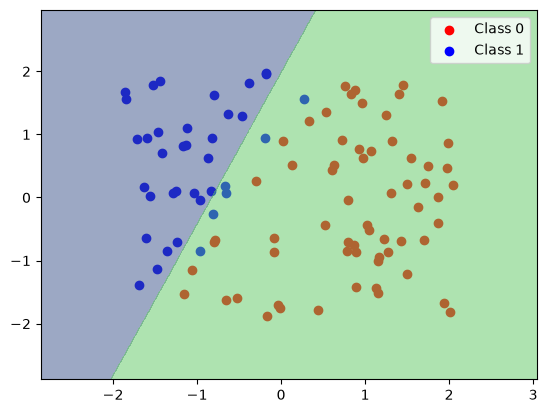

In [25]:
# TODO: fill in the logistic_error and logistic_prediction functions
from mp4 import logistic_error, logistic_prediction
from main import plot_logistic_regression_decision_boundary, plot_classification_data

A_random = np.random.randn(3, 1) # 3 because we have 2 features and 1 bias term added by get_simple_linear_features
y_preds = logistic_prediction(x, A_random, get_simple_linear_features)
error = logistic_error(y_preds, y)

print(f"Random model error: {error}")

# plot
plot_classification_data(x, y)
plot_logistic_regression_decision_boundary(A_random, x, get_simple_linear_features)
plt.legend()
plt.show()

In [26]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_logistic_prediction()
tests.test_logistic_error()

### Loss

In this probabilistic view our objective changes. Instead of minimizing squared error, we maximize the likelihood of seeing the data under our model. In other words, we think of the data as coming from an underlying distribution, and ask: if our learned model were the true one, what is the probability that sampling from that distribution would produce the training data? A good model is one which maximizes this probability. This approach is called **maximum likelihood estimation (MLE)**.

Let's start by writing down this probability given our dataset $\mathcal{D} = \{(x_i, y_i)\}_{i=0}^n$:

$$
p(\mathcal{D}) = \prod_i p(y_i \mid x_i).
$$

This assumes that each element of the dataset was sampled *independently*.

Our goal is to produce an estimator $f$ which maximizes this quantity:

$$
f = \argmax_f \mathcal{L}(f ; \mathcal{D})
= \argmax_f \prod_{i : y_i = 1} f(x_i) \prod_{i : y_i = 0} (1-f(x_i)).
$$

Learning a single $f$ for the data makes a second assumption: that each element of the dataset was sampled *identically*. Together, these are the core assumptions of MLE, that we have independent and identically distributed, or IID, data.

In practice products are inconvenient because a large product of terms between $0$ and $1$ can underflow to zero. Therefore instead of maximizing the product we use one of the most common tricks in machine learning: take the log. The logarithm is monotonically increasing, which means maximizing $f$ is equivalent to maximizing $\log(f)$. Moreover, the log of a product is the sum of the logs:

$$
f = \argmax_f \sum_{i : y_i = 1} \log(f(x_i)) + \sum_{i : y_i = 0} \log(1-f(x_i)).
$$

One last trick, for convenience, is to combine those two summations into one that uses the labels as part of the loss, and to turn the maximization into a minimization for gradient descent by negating:

$$
f = \argmin_f \sum_i -y_i \log(f(x_i)) - (1-y_i)\log(1-f(x_i)).
$$

This loss is called the *negative log likelihood*, or NLL. Implement `logistic_loss(y_pred, y_true)` using vectorized NumPy operations. Do not use a loop. Since $\log(0)$ is undefined, clip probabilities to a small interval such as $[\epsilon, 1-\epsilon]$ before taking logs.

In [27]:
# TODO: fill in the logistic_loss function
from mp4 import logistic_loss

# notice that our loss is not the same as our error 
# - error measures how many predictions our model got wrong
# - loss measures the (negative log) likelihood of the data given our model
# our model (above) is random so naturally the likelihood of the data given our model is low
loss = logistic_loss(y_preds, y)
print(f"Random model loss: {loss}")
print(f"Random model error: {error}")
print(f"Likelihood of data given random model: {np.exp(-loss)}")

Random model loss: 291.9767885830835
Random model error: 0.94
Likelihood of data given random model: 1.5706950480516696e-127


In [28]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_logistic_loss()

### Optimization

Now that we've written down our objective as a loss, we can minimize it with gradient descent. We'll use the fact that $\frac{d}{dx} \log(x) = \frac{1}{x}$ and that $\frac{d}{dx} \sigma(x) = \sigma(x)(1-\sigma(x))$. Finally, recall that $f(X) = \sigma(XA)$ for parameters $A$.

$$
\frac{\partial \mathcal{L}}{\partial A}
= \sum_i (\sigma(x_iA) - y_i)x_i.
$$

With vectorization we can write this as:

$$
\nabla_A L(A) = X^T(\hat{Y} - Y),
$$

where $\hat{Y} = \sigma(XA)$.

Compute this gradient in `get_logistic_regression_gradient(A, X, y)`. Since `X` is already the modified feature matrix, you can call `logistic_prediction` with an identity feature transform, for example:

```python
logistic_prediction(X, A, lambda x: x)
```

GD model error: 0.01
GD model loss: nan
Likelihood of data given GD model: nan


/Users/davidgray/git/cs440/CS440-MP4/mp4.py:221: RuntimeWarning: divide by zero encountered in log
  return np.min(np.sum(-y_true * np.log(y_pred) - (1 - y_true) * np.log(1 - y_pred)))
/Users/davidgray/git/cs440/CS440-MP4/mp4.py:221: RuntimeWarning: invalid value encountered in multiply
  return np.min(np.sum(-y_true * np.log(y_pred) - (1 - y_true) * np.log(1 - y_pred)))


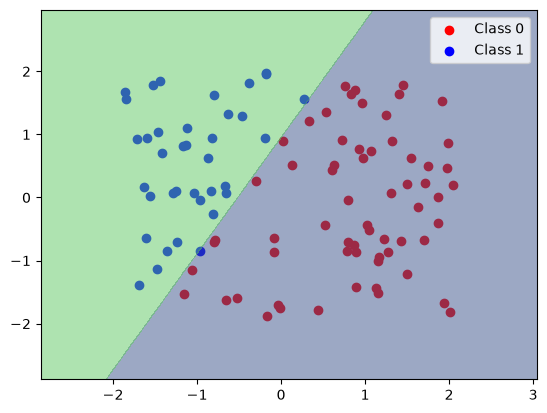

In [29]:
# TODO: fill in the get_logistic_regression_gradient function
from mp4 import get_logistic_regression_gradient

def do_gd_for_logistic(x,y,get_features):
    X = get_features(x)
    A_init = np.random.randn(X.shape[1], 1)
    learning_rate = 0.001
    num_iterations = 100000
    get_gradient = lambda A: get_logistic_regression_gradient(A, X, y)
    predicted_A = gradient_descent(get_gradient, A_init, learning_rate, num_iterations)

    # compute final loss and error
    y_preds = logistic_prediction(x, predicted_A, get_features)
    error = logistic_error(y_preds, y)
    loss = logistic_loss(y_preds, y)
    print(f"GD model error: {error}")
    print(f"GD model loss: {loss}")
    print(f"Likelihood of data given GD model: {np.exp(-loss)}")

    # plot
    plot_classification_data(x, y)
    plot_logistic_regression_decision_boundary(predicted_A, x, get_features)
    plt.legend()
    plt.show()


# Now do gradient descent
x,y = load_data(0)
do_gd_for_logistic(x,y,get_simple_linear_features)

In [30]:
# do not move on until these tests pass (they should print nothing if they pass)
tests.test_logistic_regression_gradient()

Now we load the second set of data... can you correctly classify it with a linear model?

GD model error: 0.34
GD model loss: 64.05213232238515
Likelihood of data given GD model: 1.522342522033198e-28


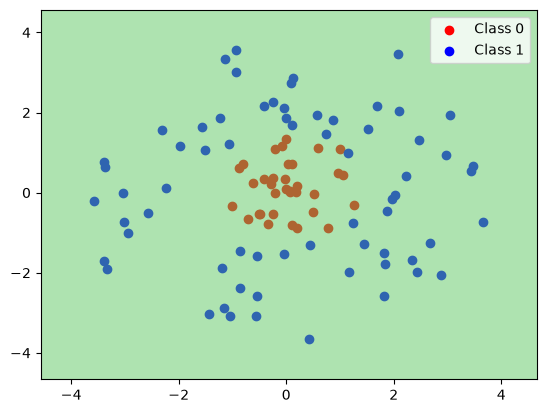

In [31]:
x,y = load_data(1)
do_gd_for_logistic(x,y,get_simple_linear_features)

Obviously a linear classification boundary cannot separate this data properly. Let's try our polynomial features from before...

GD model error: 0.0
GD model loss: nan
Likelihood of data given GD model: nan


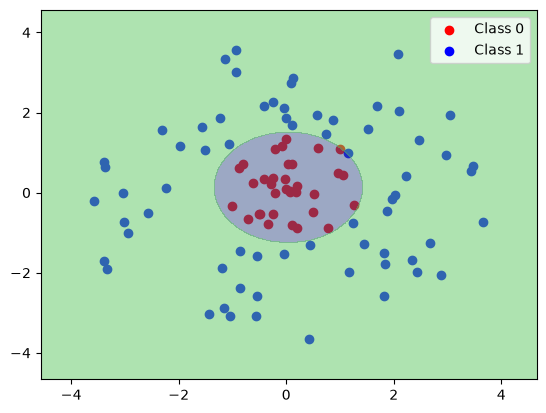

In [32]:
# Now do gradient descent
x,y = load_data(1)
get_features = lambda x: get_polynomial_features(x, degree=2)
do_gd_for_logistic(x,y,get_features)

## Third classification dataset - better features

The features we've used thus far, linear and polynomial, do not work well for the third dataset (`load_data(2)`). Your job is now to design a new set of features by filling in `get_logistic_regression_features(x)`.

Your returned feature matrix must:

- Have one row per data point
- Contain only finite values
- Work for all three provided classification datasets, not just the third dataset
- Allow gradient descent and stochastic gradient descent to reach at least 90% accuracy on each provided dataset

This is intentionally open-ended. You can combine simple features, polynomial-style features, distances, products, or other transformations, as long as the same function works across all three datasets.

GD model error: 0.01
GD model loss: nan
Likelihood of data given GD model: nan


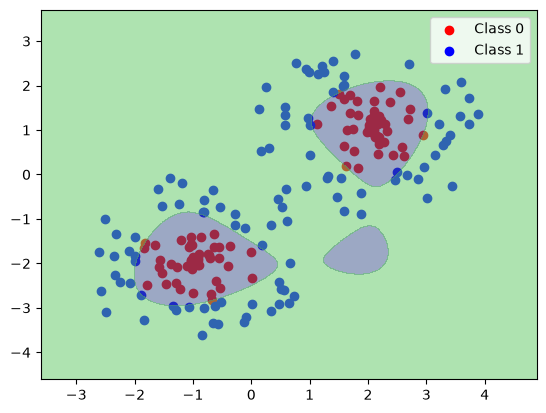

In [33]:
from mp4 import get_logistic_regression_features

x, y = load_data(2)
do_gd_for_logistic(x, y, get_logistic_regression_features)

In [34]:
# final test - will raise an error if it fails
tests.test_get_logistic_regression_features()

Testing data 0 GD
0.0
Testing data 0 SGD
0.0
Testing data 1 GD
0.0
Testing data 1 SGD
0.0
Testing data 2 GD
0.04
Testing data 2 SGD


/Users/davidgray/git/cs440/CS440-MP4/mp4.py:213: RuntimeWarning: overflow encountered in power
  return 1 / (1 + np.e ** -z)


0.02


# 7. Predicate classification and model selection

In task planning, a symbolic state describes facts such as `block_a_is_clear` or `block_b_is_on_block_c`. Here you will infer 36 Boolean predicates from 784 noisy perception features. Each predicate has its own logistic-regression weight vector, so the parameter matrix has shape `(785, 36)`, including a final bias row. The provided `predicate_prediction` applies your Part 6 logistic prediction to all columns at once.

The notebook splits the supplied training data into 270 training examples and 90 validation examples using a fixed seed. We will use the training examples to learn weights and preprocessing statistics, and validation exact match to select models. **Exact match** is the fraction of observations for which all 36 predictions are correct, after thresholding probabilities at `0.5`. Keep the 400 test examples for evaluating the selected model at the end.

In [35]:
import predicate_classifier as pc
from IPython.display import Markdown, display
from tests import (
    test_predicate_loss,
    test_predicate_gradient,
    _load_predicate_split,
    evaluate_predicate_model,
    test_predicate_preprocess_data,
    test_predicate_positive_weights,
    test_predicate_training_performance,
)

# We split our data into training, validation, and test sets
# The training set is used to fit the model,
# the validation set is used to tune hyperparameters,
# and the test set is used to evaluate the final model
train_X, train_y, val_X, val_y, test_X, test_y = _load_predicate_split()
print("fit/validation/test shapes:", train_X.shape, val_X.shape, test_X.shape)

fit/validation/test shapes: (270, 784) (90, 784) (400, 784)


## 7.1 Train a plain multi-label baseline

Our relevant matrices are:

$$
X \in \mathbb{R}^{N \times (d+1)}, \qquad W \in \mathbb{R}^{(d+1) \times P}, \qquad \hat{Y}=\sigma(XW).
$$

We will begin by fitting a plain multi-label logistic regression model without any model selection.

### Implement `compute_loss`

Implement ordinary binary cross-entropy summed over the 36 predicates and averaged over examples:

$$
L_{\text{data}}(W) = -\frac{1}{N}\sum_{i=1}^{N}\sum_{j=1}^{P}
\left[y_{ij}\log(\hat y_{ij}) + (1-y_{ij})\log(1-\hat y_{ij})\right].
$$

The template computes predictions and clips them to $[10^{-8},1-10^{-8}]$ to avoid `log(0)`. Compute the BCE for each entry and sum all entries before dividing by `X.shape[0]`. Store the scalar result in `bce`.

We train with this smooth loss and evaluate with **exact-match accuracy**: threshold probabilities at 0.5, then count an observation as correct only if all 36 labels match. A lower BCE does not always mean a higher exact-match score.


In [39]:
# TODO: implement the unregularized and unweighted path through compute_loss
test_predicate_loss("baseline")

### Implement `compute_gradient`

Next implement the gradient for the same baseline objective. The derivative of BCE with a sigmoid output simplifies to the prediction error, giving

$$
\nabla_W L_{\text{data}} = \frac{1}{N}X^T(\hat Y-Y).
$$

Check the matrix shapes before writing code: $X^T$ has shape `(num_features + 1, num_samples)` and $(\hat Y-Y)$ has shape `(num_samples, num_predicates)`, so the result has exactly the same shape as $W$. Store the result in `gradient`, with shape `(num_features + 1, num_predicates)`.

In [40]:
# TODO: implement the unregularized and unweighted path through compute_gradient
test_predicate_gradient("baseline")

### Train with the provided SGD loop

`train_model` is provided. It shuffles the training examples, takes 9000 mini-batch gradient updates, and records training and validation scores every 50 updates. It returns the weights from the first checkpoint with the highest validation exact match. This lets validation data choose how much training is useful.

Run the baseline and inspect its curves. Does the checkpoint with the lowest training loss also have the highest validation exact match? Or do we have some overfitting...


| Components | Validation exact match |
|:---|---:|
| Baseline | 27.8% |

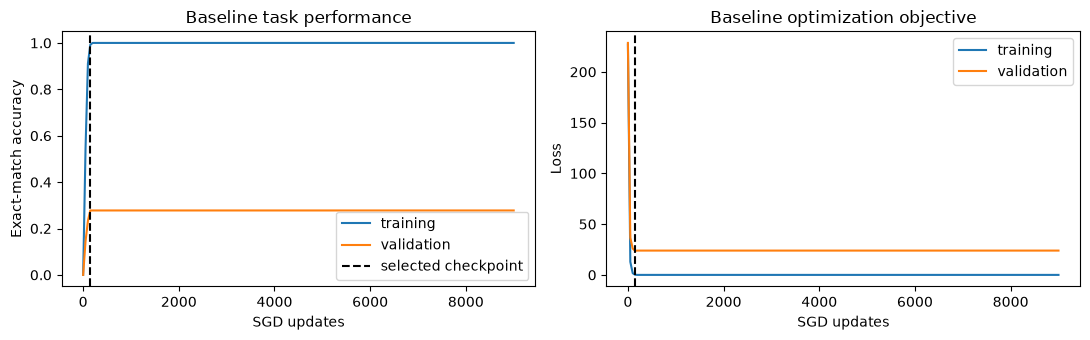

In [41]:
ablation_rows = {}

def run_ablation_row(index, name):
    # load the config for this ablation row
    config = pc.ABLATION_CONFIGS[index]
    # train model on training data and evaluate on validation data, use seed for reproducibility
    model, history = pc.train_model(train_X, train_y, val_X, val_y, **config, seed=7)
    # save the results in a dictionary for later display
    row = {
        "components": name,
        "config": config,
        "validation": evaluate_predicate_model(model, val_X, val_y),
        "selected_update": history[-1]["selected_update"],
        "model": model,
        "history": history,
    }
    ablation_rows[index] = row
    return row

# some nice formatting of results in a table
def display_ablation_table(indices=None):
    if indices is None:
        indices = sorted(ablation_rows)
    lines = ["| Components | Validation exact match |", "|:---|---:|"]
    for index in indices:
        row = ablation_rows[index]
        lines.append(f'| {row["components"]} | {row["validation"]["exact_match"]:.1%} |')
    display(Markdown("\n".join(lines)))

# for now we will just run the baseline and display its results
baseline_row = run_ablation_row(0, "Baseline")
display_ablation_table([0])

# plot the training and validation curves for the baseline... do you see overfitting?
baseline_history = baseline_row["history"]
updates = [row["update"] for row in baseline_history]
selected_update = baseline_history[-1]["selected_update"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(updates, [row["train_exact_match"] for row in baseline_history], label="training")
axes[0].plot(updates, [row["val_exact_match"] for row in baseline_history], label="validation")
axes[0].axvline(selected_update, color="black", linestyle="--", label="selected checkpoint")
axes[0].set_xlabel("SGD updates")
axes[0].set_ylabel("Exact-match accuracy")
axes[0].set_title("Baseline task performance")
axes[0].legend()
axes[1].plot(updates, [row["train_loss"] for row in baseline_history], label="training")
axes[1].plot(updates, [row["val_loss"] for row in baseline_history], label="validation")
axes[1].axvline(selected_update, color="black", linestyle="--")
axes[1].set_xlabel("SGD updates")
axes[1].set_ylabel("Loss")
axes[1].set_title("Baseline optimization objective")
axes[1].legend()
plt.tight_layout()
plt.show()

Next we will incrementally add some model selection techniques to improve the baseline one by one.

## 7.2 Normalize the inputs

Inspect the means and standard deviations of the 784 input features. Each histogram counts features whose mean or standard deviation falls within a given bin.

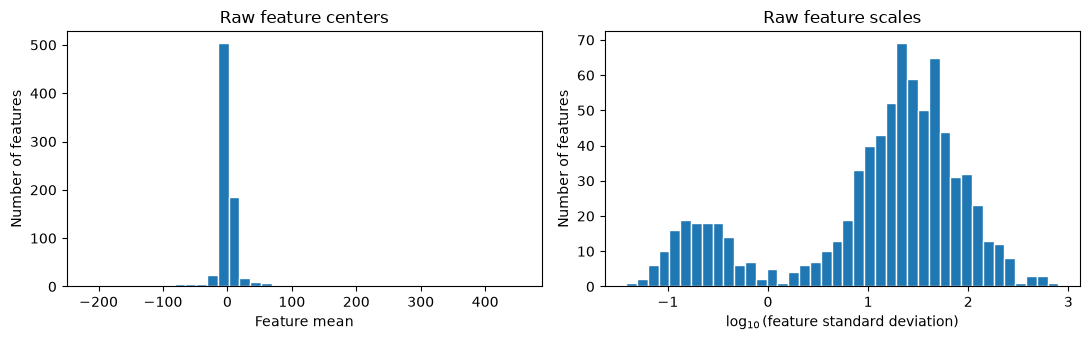

Feature means range from -216 to 455
Smallest feature std: 0.0384
Largest feature std:  795


In [42]:
raw_feature_mean = train_X.mean(axis=0)
raw_feature_std = train_X.std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(raw_feature_mean, bins=40, edgecolor="white")
axes[0].set_xlabel("Feature mean")
axes[0].set_ylabel("Number of features")
axes[0].set_title("Raw feature centers")
# A logarithmic horizontal axis exposes the many different feature scales
axes[1].hist(np.log10(np.maximum(raw_feature_std, 1e-12)), bins=40, edgecolor="white")
axes[1].set_xlabel(r"$\log_{10}$(feature standard deviation)")
axes[1].set_ylabel("Number of features")
axes[1].set_title("Raw feature scales")
plt.tight_layout()
plt.show()
print(f"Feature means range from {raw_feature_mean.min():.3g} to {raw_feature_mean.max():.3g}")
print(f"Smallest feature std: {raw_feature_std.min():.3g}")
print(f"Largest feature std:  {raw_feature_std.max():.3g}")

The features have different means and scales. Since feature values multiply prediction errors in the gradient, large values can dominate the update even when smaller features are useful. We can center and scale each feature before training.

Standardize each feature using statistics fitted on the training split:

$$
\mu_k = \frac{1}{N}\sum_i X_{ik}, \qquad
s_k = \sqrt{\frac{1}{N}\sum_i (X_{ik}-\mu_k)^2}, \qquad
X'_{ik}=\frac{X_{ik}-\mu_k}{s_k}.
$$

Replace any $s_k<10^{-8}$ with $1$ so a constant feature becomes zero instead of producing a division by zero. Save $\mu$ and $s$, each with shape `(1, num_features)`, in `PreprocessState` and reuse those **training** statistics for validation and test data. Recomputing them on another split would leak information and give the model a different coordinate system. Append the bias column only after normalization; otherwise normalization would turn it into zeros.

Complete the normalization path in `preprocess_data`, verify the transformed distributions, then retrain the otherwise unchanged baseline. Compare its validation score with the baseline.

In [68]:
# TODO: add the normalization path to preprocess_data
test_predicate_preprocess_data()

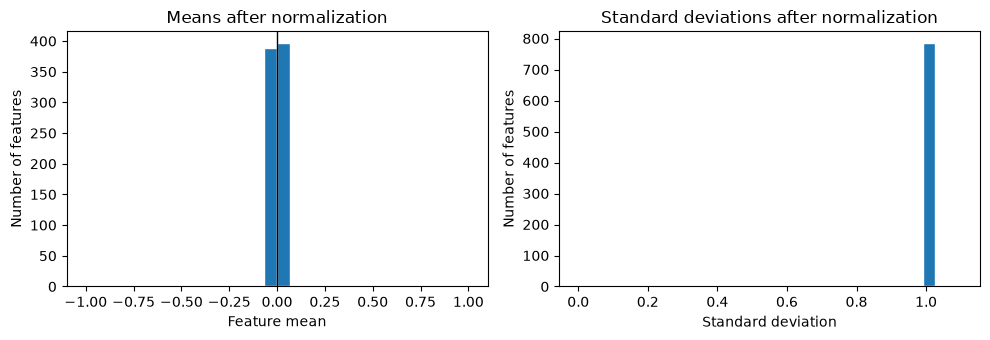

Largest absolute normalized mean: 2.06e-05
train/validation shapes after adding bias: (270, 785) (90, 785)


| Components | Validation exact match |
|:---|---:|
| Baseline | 27.8% |
| Normalization | 58.9% |

In [69]:
# compute the normalization hyperparameters on the training set
normalized_train_X, fitted_preprocessing = pc.preprocess_data(train_X, normalize=True)
# apply the same normalization to the validation set (using the training set's hyperparameters)
normalized_val_X, _ = pc.preprocess_data(val_X, preprocessing=fitted_preprocessing)

# recompute mean and std after normalization to see difference
normalized_feature_mean = normalized_train_X[:, :-1].mean(axis=0)
normalized_feature_std = normalized_train_X[:, :-1].std(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(normalized_feature_mean, bins=30, range=(-1, 1), edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_xlabel("Feature mean")
axes[0].set_ylabel("Number of features")
axes[0].set_title("Means after normalization")
axes[1].hist(normalized_feature_std, bins=30, range=(0, 1.1), edgecolor="white")
axes[1].set_xlabel("Standard deviation")
axes[1].set_ylabel("Number of features")
axes[1].set_title("Standard deviations after normalization")
plt.tight_layout()
plt.show()
print(f"Largest absolute normalized mean: {np.abs(normalized_feature_mean).max():.3g}")
print("train/validation shapes after adding bias:", normalized_train_X.shape, normalized_val_X.shape)

# retrain the model with normalization and display both the earlier baseline and new normalization results
run_ablation_row(1, "Normalization")
display_ablation_table([0, 1])

## 7.3 Regularize the model

Normalization helps optimization, but there are still 784 inputs and only 270 training examples. The classifier can fit noise in the training data. We now add regularization to penalize large coefficients, and more specifically we add L1 regularization to encourage the model to only use informative features.

### Extend `compute_loss`

Let $W_{\mathrm{nb}}$ be `weights[:-1]`, with shape `(num_features, num_predicates)`. The regularized objective is

$$
L(W)=L_{\text{data}}(W)
+\lambda_1\lVert W_{\mathrm{nb}}\rVert_1.
$$

L1 encourages the model to ignore nuisance features. Add this penalty to `compute_loss`, leaving out the bias row.

In [ ]:
# TODO: add the non-bias L1 penalty to compute_loss
test_predicate_loss("regularized")

### Extend `compute_gradient`

The L1 penalty contributes $\lambda_1\operatorname{sign}(W_{\mathrm{nb}})$ to the gradient, giving

$$
(\nabla_W L)_{\mathrm{nb}} = (\nabla_W L_{\text{data}})_{\mathrm{nb}}
+\lambda_1\operatorname{sign}(W_{\mathrm{nb}}).
$$

Add this term to `gradient[:-1]`, with shape `(num_features, num_predicates)`. Leave the bias gradient unchanged. After the gradient test passes, retrain with normalization and L1 enabled and inspect how the coefficient distribution changes.

In [ ]:
# TODO: add the non-bias L1 term to compute_gradient
test_predicate_gradient("regularized")

In [ ]:
# retrain the model with normalization and L1 regularization and display all three ablation results
run_ablation_row(4, "Normalization + L1")
display_ablation_table([0, 1, 4])

# plot the weight distributions for the normalization and normalization + L1 ablation rows
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for index, label in [(1, "Normalization"), (4, "Normalization + L1")]:
    non_bias_weights = np.abs(ablation_rows[index]["model"].weights[:-1]).ravel()
    ax.hist(
        np.log10(non_bias_weights + 1e-8), bins=45, density=True,
        histtype="step", linewidth=1.5, label=label,
    )
ax.set_xlabel(r"$\log_{10}(|w| + 10^{-8})$")
ax.set_ylabel("Density")
ax.set_title("L1 shifts weights toward zero (note the LOG scale)")
ax.legend()
plt.tight_layout()
plt.show()

## 7.4 Give rare positive labels more weight

The results above are really quite good but there is more that can be done. We'll add just one more technique, though again, there are many options.

Inspect how often each predicate is true in the training data. For a rare predicate, BCE includes many more negative than positive examples. A model can therefore have high per-predicate accuracy while missing rare positive labels - this is poor inductive bias. Each missed label also makes the entire state prediction incorrect so really harms our exact match performance.

In [ ]:
positive_counts = train_y.sum(axis=0)
sorted_predicates = np.argsort(positive_counts)
plt.figure(figsize=(10, 3.5))
plt.bar(np.arange(train_y.shape[1]), positive_counts[sorted_predicates])
plt.xlabel("Predicates, sorted from rarest to most common")
plt.ylabel("Positive training examples")
plt.title("The predicate labels are imbalanced")
plt.show()

### Extend `get_positive_weights`

For predicate $j$, multiply the loss of a positive example by

$$
c_j = \operatorname{clip}\left(\left(\frac{n_j^-}{\max(n_j^+,1)}\right)^p,\ 0.5,\ 20\right),
$$

where $n_j^+$ and $n_j^-$ are its positive and negative counts. The exponent $p$ controls the strength: $p=0$ returns all ones, while $p=1$ uses the full class ratio. Clipping limits the influence of any one positive example.

Return an array with shape `(num_predicates,)` from `get_positive_weights`, run its test, and compare each predicate's positive frequency with its weight.

In [ ]:
# TODO: implement nonuniform positive weights
test_predicate_positive_weights()

In [ ]:
positive_rates = train_y.mean(axis=0)
positive_weights = pc.get_positive_weights(train_y, pc.POSITIVE_WEIGHT_POWER)
plt.scatter(positive_rates, positive_weights)
plt.xlabel("Fraction of training examples that are positive")
plt.ylabel("Weight on a positive example")
plt.title("Rare positive labels receive more weight")
plt.show()

### Extend `compute_loss` with label weights

Let $a_{ij}=c_j$ when $y_{ij}=1$, and $a_{ij}=1$ otherwise. The weighted data loss is

$$
L_{\text{data}}(W) = -\frac{1}{N}\sum_{i=1}^{N}\sum_{j=1}^{P}
a_{ij}\left[y_{ij}\log(\hat y_{ij}) + (1-y_{ij})\log(1-\hat y_{ij})\right].
$$

Which is the same BCE as before except each term is now multiplied by its corresponding $a_{ij}$.

In [ ]:
# TODO: apply positive weights in compute_loss
test_predicate_loss("weighted")

### Extend `compute_gradient` with label weights

Weighting also multiplies the corresponding prediction errors in the gradient:

$$
\nabla_W L_{\text{data}} = \frac{1}{N}X^T\left(A\odot(\hat Y-Y)\right).
$$

Where $\odot$ denotes element-wise multiplication, and $A$ is the matrix of label weights.

After running the test below, retrain with normalization, L1, and positive weighting enabled, and compare the validation scores.

In [ ]:
# TODO: apply positive weights in compute_gradient
test_predicate_gradient("weighted")

run_ablation_row(7, "Normalization + L1 + positive weighting")
display_ablation_table([0, 1, 4, 7])

## 7.5 Complete the ablation table

NOTE: you don't need to write any more code for this part, we've provided you with the rest of the necessary functions. This part is just for completeness and to help us see the full validation pipeline. 

We have added components one at a time. Now compare all subsets to see which components help on their own and which help in combination.

With three on/off choices there are $2^3=8$ configurations. Train the four remaining subsets with the same seed, keeping the learning rate, batch size, and number of updates fixed so the comparison isolates the components. Validation exact match is the column used for model selection. Keep the test split untouched until the configuration is selected.

In [ ]:
# Train only the four configurations not already evaluated
for index, name in [
    (2, "L1"),
    (3, "Positive weighting"),
    (5, "Normalization + positive weighting"),
    (6, "L1 + positive weighting"),
]:
    run_ablation_row(index, name)

display_ablation_table()

short_names = ["Base", "N", "L1", "W", "N+L1", "N+W", "L1+W", "N+L1+W"]
ordered_rows = [ablation_rows[index] for index in range(8)]
x_positions = np.arange(len(ordered_rows))
bar_width = 0.38
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(
    x_positions,
    [row["validation"]["exact_match"] for row in ordered_rows],
    bar_width,
    label="validation",
)
ax.set_xticks(x_positions, short_names, rotation=35, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Exact-match accuracy")
ax.set_title("Complete ablation results")
ax.legend()
plt.tight_layout()
plt.show()

Positive weighting helps most when combined with normalization and L1 in these results. Comparing all subsets shows interactions that we would miss by examining each component alone. Next we use validation scores to choose a configuration for the final test evaluation.


## 7.6 Model selection with the provided validation experiment

`validation_experiment` is provided; you do not need to implement it. It tries each configuration in `ABLATION_CONFIGS`, trains a model using the training split, and scores that model on the validation split using the training preprocessing statistics. It returns the first configuration with the highest validation exact match, together with the results for all eight configurations.

These configurations form a small hyperparameter search: `normalize` is either `False` or `True`, `l1_lambda` is either `0` or `0.001`, and `positive_weight_power` is either `0` or `1`. Each run uses the same seed, learning rate, batch size, and training budget so we can compare the effects of those choices. Normally we would try many more hyperparameter values, including several regularization strengths and weighting powers, as well as different learning rates and batch sizes.

Run the provided code below to select the configuration and reproduce its model with the same seed. We keep the training and validation splits separate because the provided trainer also uses validation scores to select a checkpoint. Evaluate the selected model on the test split once; test scores must not influence the hyperparameter search. In a larger workflow, after fixing the configuration and training duration, we could refit on the combined training and validation data before that final test evaluation.


In [ ]:
# Run the provided hyperparameter search and evaluate its selected model
selected_config, validation_results = pc.validation_experiment(
    train_X, train_y, val_X, val_y, seed=7
)
display(Markdown(f"**Selected from validation:** `{selected_config}`"))

model, history = pc.train_model(
    train_X, train_y, val_X, val_y, **selected_config, seed=7
)
validation_metrics = evaluate_predicate_model(model, val_X, val_y)
test_metrics = evaluate_predicate_model(model, test_X, test_y)
metric_lines = [
    "| Split | Predicate accuracy | Balanced accuracy | Mean F1 | Exact match |",
    "|:---|---:|---:|---:|---:|",
]
for split, metrics in [("Validation", validation_metrics), ("Test", test_metrics)]:
    metric_lines.append(
        f'| {split} | {metrics["predicate_accuracy"]:.1%} | '
        f'{metrics["balanced_accuracy"]:.1%} | {metrics["mean_f1"]:.1%} | '
        f'{metrics["exact_match"]:.1%} |'
    )
display(Markdown("\n".join(metric_lines)))
pc.plot_training_curves(history, "predicate_training_curve.png")

test_predicate_training_performance()

Congratulations, you should now be able to submit `mp4.py` and `predicate_classifier.py` on Gradescope.

Before submitting, comment out or remove debugging print statements, since excessive printing can slow down the autograder. Submit only `mp4.py` and `predicate_classifier.py`; do not submit the notebook, tests, `main.py`, `planar_arm.py`, or the data files.
